## Importing the Required Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Data Audit & Cleaning Blueprint

### 1.1 Load the data

In [23]:
customers = pd.read_csv('data/customers.csv', parse_dates=["signup_date"])
order_items = pd.read_csv('data/order_items.csv')
orders = pd.read_csv('data/orders.csv', parse_dates=["order_date"])
products = pd.read_csv('data/products.csv')

In [24]:
for name, frame in {"orders": orders, "order_items": order_items, "products": products, "customers": customers}.items():
    print(name, frame.shape)


orders (9245, 7)
order_items (15608, 5)
products (90, 5)
customers (3600, 4)


### 1.2 Check Duplicates in the dataset and fix them 

In [25]:
print(f"The Duplicates in Orders: {orders.duplicated().sum()}")
print(f"The Duplicates in Order Items: {order_items.duplicated().sum()}")
print(f"The Duplicates in Products: {products.duplicated().sum()}")
print(f"The Duplicates in Customers: {customers.duplicated().sum()}")

The Duplicates in Orders: 38
The Duplicates in Order Items: 0
The Duplicates in Products: 0
The Duplicates in Customers: 0


As you can see we have 38 duplicates in orders and we need to see them to identify what procedure we will take

In [26]:
orders[orders.duplicated(subset=['order_id'],keep=False)].sort_values(by='order_id')

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
47,100048,3320,2024-01-06 16:37:36,completed,credit_card,NaN,6.95
8560,100048,3320,2024-01-06 16:37:36,completed,credit_card,NaN,6.95
7556,100303,853,2024-02-03 08:33:22,completed,apple_pay,NaN,0.00
303,100303,853,2024-02-03 08:33:22,completed,apple_pay,NaN,0.00
5488,100710,526,2024-03-13 13:39:17,completed,credit_card,NaN,0.00
...,...,...,...,...,...,...,...
8617,108585,1995,2025-11-28 12:43:37,completed,apple_pay,HOLIDAY20,0.00
9104,109068,1981,2025-12-20 13:27:25,completed,credit_card,HOLIDAY20,6.95
3104,109068,1981,2025-12-20 13:27:25,completed,credit_card,HOLIDAY20,6.95
4213,109087,3358,2025-12-22 08:35:44,completed,credit_card,HOLIDAY20,0.00


now we know that they are duplicated after we checked the duplicated by order_id column

now we will drop them

In [27]:
orders_clean= orders.drop_duplicates(subset=['order_id'], keep=False).copy()

### 1.3 Standardize product categories

In [28]:
products_clean = products.copy()
products_clean['category'] = products_clean['category'].str.strip().str.title()

### 1.4 Impute missing unit prices from products list_price

In [29]:
order_items_clean = order_items.copy()
order_items_clean = order_items_clean.merge(
    products_clean[['product_id', 'list_price']], 
    on='product_id', 
    how='left'
)
order_items_clean['unit_price'] = order_items_clean['unit_price'].fillna(order_items_clean['list_price'])
order_items_clean.drop(columns=['list_price'], inplace=True)

### 1.5 Compute line-item net revenue

In [30]:
order_items_clean['item_revenue'] = (
    order_items_clean['quantity'] * order_items_clean['unit_price']
) - order_items_clean['discount_amount']

## 2. Business Metric Definition: Revenue & Order Status

In e-commerce reporting, explicitly separating gross sales from realized revenue is critical:Net Sales Revenue: Calculated as the sum of discounted item amounts for orders where status == 'completed'. Canceled orders represent zero realized sales, while returned orders are refunded and tracked separately as operational leakage.Line Item Formula:$$\text{Item Revenue} = (\text{Quantity} \times \text{Unit Price}) - \text{Discount Amount}$$Order Revenue:$$\text{Net Revenue} = \sum_{i \in \text{Completed Items}} \text{Item Revenue}_i$$

### 2.1 Merge cleaned tables into an analytical dataset 

In [31]:
df = order_items_clean.merge(orders_clean, on='order_id', how='inner')
df = df.merge(products_clean, on='product_id', how='inner')

### 2.2 Filter for completed sales

In [32]:
df_completed = df[df['status'] == 'completed'].copy()
df_completed['month_year'] = df_completed['order_date'].dt.to_period('M')
df_completed['year'] = df_completed['order_date'].dt.year
df_completed['month'] = df_completed['order_date'].dt.month

## 3. Monthly Trends & Seasonality (2024 vs. 2025)

The analysis shows steady growth across the two-year period:

Overall Growth: Net revenue grew +21.1% YoY, rising from $850,786.45 in 2024 to $1,030,488.63 in 2025.

Holiday Peak: Revenue experiences a massive annual spike in November (reaching $100.6K in 2024 and $129.9K in 2025) driven by Black Friday / Cyber Monday promotions.

Summer Lift: A secondary seasonal bump occurs between June and August, fueled by outdoor furniture and decor demand.

### 3.1 Monthly pivot table for YoY comparison

In [34]:
monthly_rev = df_completed.pivot_table(
    index='month', 
    columns='year', 
    values='item_revenue', 
    aggfunc='sum'
)
monthly_rev['YoY_Growth_%'] = ((monthly_rev[2025] - monthly_rev[2024]) / monthly_rev[2024]) * 100
print(monthly_rev)

year        2024       2025  YoY_Growth_%
month                                    
1       54327.52   71843.19     32.240879
2       63064.65   69538.05     10.264705
3       71371.42   78398.48      9.845762
4       64768.74   79515.73     22.768684
5       73542.85   83113.31     13.013447
6       66985.40   92184.78     37.619213
7       76707.06   83372.59      8.689591
8       62162.60   90405.55     45.433991
9       60054.02   75165.48     25.163111
10      68387.83   81330.47     18.925356
11     100507.25  129426.08     28.772880
12      86497.00   90924.28      5.118420


## 4. Category Dynamics, Return Rates, & AOV

Analyzing performance by product category reveals stark differences in average order value (AOV) and return risk:

Top Revenue Drivers: Furniture ($322.8K total) and Kitchen ($279.7K total) generate the highest total revenue.

Fastest Growing Category: Storage led growth at +40.8% YoY ($58.0K in 2024 to $81.6K in 2025), followed by Kitchen (+26.2%).

High-Value vs. High-Return:

Furniture yields the highest AOV ($376.19) but suffers from an 11.72% return rate—nearly triple the site average (4–5%).

Lighting ($208.18 AOV) and Outdoor ($199.21 AOV) maintain strong margins with normal return rates (~4.0% and ~4.4%).

Bath recorded the highest cancellation rate (4.56%).

### 4.1 Category performance summary

In [35]:
cat_perf = df_completed.groupby('category').agg(
    total_revenue=('item_revenue', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()
cat_perf['AOV'] = cat_perf['total_revenue'] / cat_perf['orders']

### 4.2 Return & Cancellation rate per category across all orders

In [36]:
cat_status = df.groupby(['category', 'status'])['order_id'].nunique().unstack(fill_value=0)
cat_status['total_orders'] = cat_status.sum(axis=1)
cat_status['return_rate_%'] = (cat_status['returned'] / cat_status['total_orders']) * 100
cat_status['cancel_rate_%'] = (cat_status['canceled'] / cat_status['total_orders']) * 100

## 5. Visualizations for Executive Pitch

### Chart 1: Monthly Revenue YoY Trend

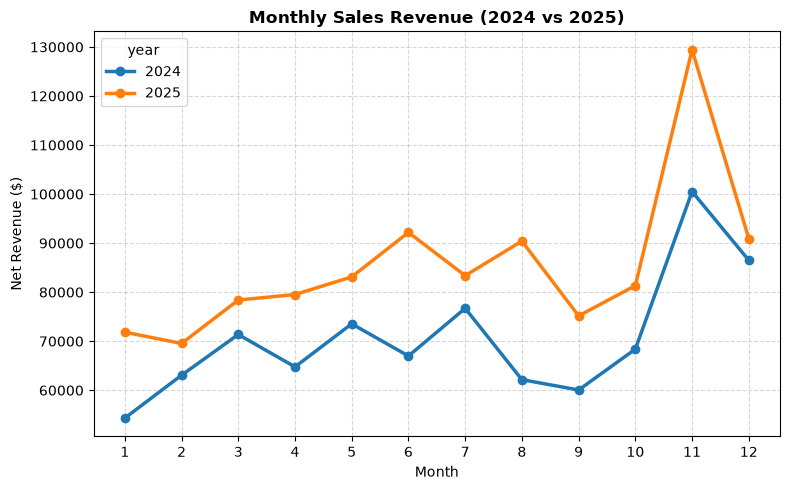

In [39]:
plt.figure(figsize=(8, 5))
monthly_rev[[2024, 2025]].plot(kind='line', marker='o', linewidth=2.5, ax=plt.gca())
plt.title('Monthly Sales Revenue (2024 vs 2025)', fontsize=12, fontweight='bold')
plt.ylabel('Net Revenue ($)')
plt.xlabel('Month')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('chart1_monthly_revenue.png', dpi=300)
plt.show()

### Chart 2: Category Revenue Comparison

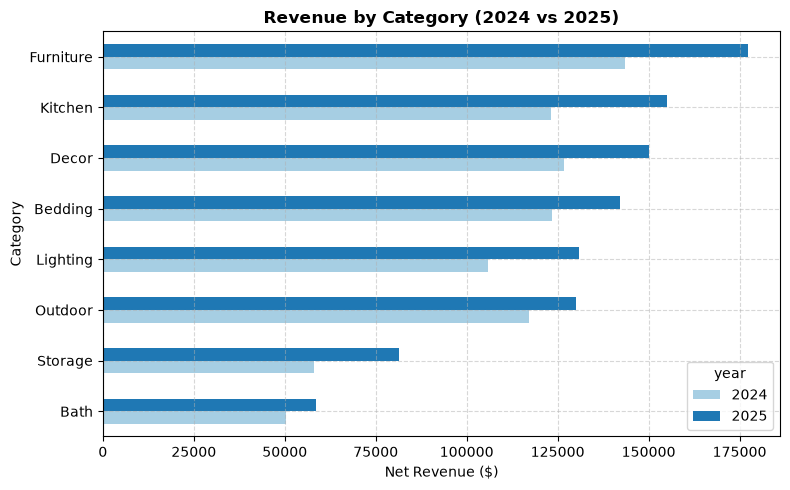

In [40]:
cat_rev = df_completed.groupby(['category', 'year'])['item_revenue'].sum().unstack()

plt.figure(figsize=(8, 5))
cat_rev.sort_values(by=2025).plot(kind='barh', color=['#a6cee3', '#1f78b4'], ax=plt.gca())
plt.title('Revenue by Category (2024 vs 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Net Revenue ($)')
plt.ylabel('Category')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('chart2_category_revenue.png', dpi=300)
plt.show()

### Chart 3: Return Rate vs AOV Risk Matrix

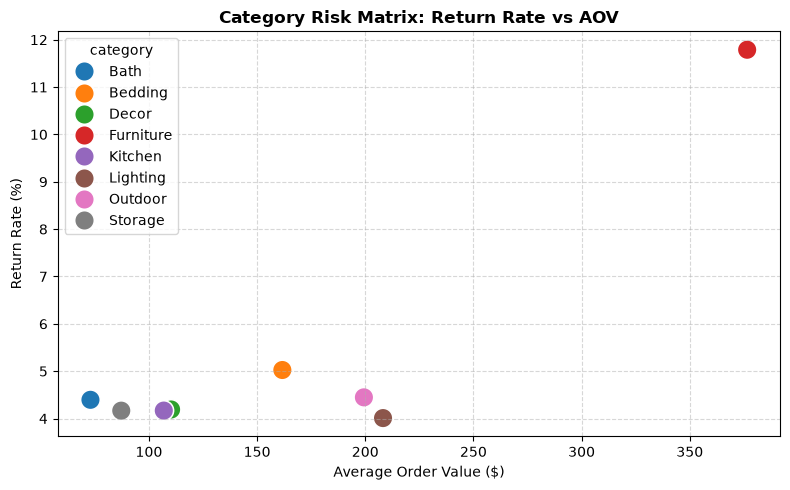

In [41]:
cat_matrix = cat_perf.merge(cat_status[['return_rate_%']], on='category')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=cat_matrix, x='AOV', y='return_rate_%', hue='category', s=200, ax=plt.gca())
plt.title('Category Risk Matrix: Return Rate vs AOV', fontsize=12, fontweight='bold')
plt.xlabel('Average Order Value ($)')
plt.ylabel('Return Rate (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('chart3_risk_matrix.png', dpi=300)
plt.show()